# Per-Layout Parameter-Estimation Convergence

Relative-error convergence (mean ± std across repeated runs) for the joint
estimation of **leak area**, **roughness multiplier**, and **demand multiplier**
as a function of EM round, evaluated separately for three sensor layouts.

Each layout uses scenario `H2Q2` (2 pressure + 2 flow sensors); the rows below
differ only in *where* the sensors are placed.

| Layout | # of repeated runs averaged | Notes |
|--------|-----------------------------|-------|
| 7      | 10 (v1–v10)                 | Best-converging placement |
| 2      | 5  (v1–v5)                  | Converges, slower on roughness |
| 4      | 5  (v1–v5)                  | Leak area & demand do not converge to zero |

Data files live in `../../data/per-layout-results/`.


## Imports

In [1]:
import pandas as pd


## Load per-layout parameter-estimate CSVs

In [2]:


estimates7_H2Q2_v1=pd.read_csv('../data/fig_8/parameter_estimates7_H2Q2_v1.csv')
estimates7_H2Q2_v2=pd.read_csv('../data/fig_8/parameter_estimates7_H2Q2_v2.csv')
estimates7_H2Q2_v3=pd.read_csv('../data/fig_8/parameter_estimates7_H2Q2_v3.csv')
estimates7_H2Q2_v4=pd.read_csv('../data/fig_8/parameter_estimates7_H2Q2_v4.csv')
estimates7_H2Q2_v5=pd.read_csv('../data/fig_8/parameter_estimates7_H2Q2_v5.csv')

estimates2_H2Q2_v1=pd.read_csv('../data/fig_8/parameter_estimates2_H2Q2_v1.csv')
estimates2_H2Q2_v2=pd.read_csv('../data/fig_8/parameter_estimates2_H2Q2_v2.csv')
estimates2_H2Q2_v3=pd.read_csv('../data/fig_8/parameter_estimates2_H2Q2_v3.csv')
estimates2_H2Q2_v4=pd.read_csv('../data/fig_8/parameter_estimates2_H2Q2_v4.csv')
estimates2_H2Q2_v5=pd.read_csv('../data/fig_8/parameter_estimates2_H2Q2_v5.csv')

estimates4_H2Q2_v1=pd.read_csv('../data/fig_8/parameter_estimates4_H2Q2_v1.csv')
estimates4_H2Q2_v2=pd.read_csv('../data/fig_8/parameter_estimates4_H2Q2_v2.csv')
estimates4_H2Q2_v3=pd.read_csv('../data/fig_8/parameter_estimates4_H2Q2_v3.csv')
estimates4_H2Q2_v4=pd.read_csv('../data/fig_8/parameter_estimates4_H2Q2_v4.csv')
estimates4_H2Q2_v5=pd.read_csv('../data/fig_8/parameter_estimates4_H2Q2_v5.csv')

## Network with sensor and leak locations

Each layout row pairs a small PA2 network map (showing sensor/leak placement)
with the error-convergence panels below it.

* **Yellow star** — pressure sensor (`H1`, `H2`, … at superjunctions)
* **Blue star**   — flow sensor (`Q1`, `Q2`, … at superlink midpoints)
* **Red star**    — leak location used in each version `v1` … `vN`
* **Red line**    — pump (from `PA2__pumps.csv`)

The PA2 network geometry is loaded from `../simulation/`.


In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import numpy as np

SJ_ALL = pd.read_csv('../data/fig_7/superjunctions_PA2_inp.csv', index_col=0)
SL_ALL = pd.read_csv('../data/fig_7/PA2__superlinks.csv',        index_col=0)
PUMPS  = pd.read_csv('../data/fig_7/PA2__pumps.csv',             index_col=0)

# id=263 is the leak-sink pseudo-junction with placeholder coordinates; drop it for plotting
SJ = SJ_ALL[SJ_ALL['id'] != 263].copy()
SL = SL_ALL[(SL_ALL['sj_0'] != 263) & (SL_ALL['sj_1'] != 263)].copy()

ID_TO_XY = dict(zip(SJ['id'], zip(SJ['map_x'], SJ['map_y'])))


def _draw_network(ax, press_ids, flow_ids, leak_ids,
                  draw_markers=True, edge_lw=1.5, pump_lw=2.0,
                  star_size=80, label_fontsize=9, label_offset=(5, -10)):
    """Render the PA2 network onto `ax`. Used by both the main plot and the inset.

    Z-order for stars: V (red) and Q (blue) at zorder=5, H (gold) at zorder=6
    so the yellow pressure-sensor stars always sit on top.
    """
    for _, e in SL.iterrows():
        x0, y0 = ID_TO_XY[int(e['sj_0'])]
        x1, y1 = ID_TO_XY[int(e['sj_1'])]
        ax.plot([x0, x1], [y0, y1], color='0.4', linewidth=edge_lw, zorder=1)
    ax.scatter(SJ['map_x'], SJ['map_y'], s=3, color='0.5', zorder=2)
    for _, p in PUMPS.iterrows():
        x0, y0 = ID_TO_XY[int(p['sj_0'])]
        x1, y1 = ID_TO_XY[int(p['sj_1'])]
        ax.plot([x0, x1], [y0, y1], color='k', linewidth=pump_lw, zorder=3)

    if not draw_markers:
        return

    def _star(x, y, label, color, markersize, zorder=5, marker='*', edgecolors='none', linewidths=0.6):
        ax.scatter(x, y, marker=marker, s=markersize, facecolors=color,
                   linewidths=linewidths, zorder=zorder, edgecolors=edgecolors)
        #ax.annotate(label, (x, y), xytext=label_offset,
        #            textcoords='offset points',
        #            fontsize=label_fontsize, fontweight='bold',
        #            zorder=zorder + 1)

    for k, jid in enumerate(leak_ids, 1):
        _star(*ID_TO_XY[int(jid)], f'V{k}', 'none', 1*star_size,      zorder=5, marker='o', edgecolors='#E15759', linewidths=2)
    for k, lid in enumerate(flow_ids, 1):
        e  = SL.loc[SL['id'] == int(lid)].iloc[0]
        x0, y0 = ID_TO_XY[int(e['sj_0'])]
        x1, y1 = ID_TO_XY[int(e['sj_1'])]
        _star((x0 + x1) / 2, (y0 + y1) / 2, f'Q{k}', '#76B7B2', star_size, zorder=5, marker='X')
    # pressure sensors drawn last with higher zorder -> always on top
    for k, jid in enumerate(press_ids, 1):
        _star(*ID_TO_XY[int(jid)], f'H{k}', '#F28E2B', star_size,     zorder=6, marker='P')


def plot_pa2_layout(press_ids, flow_ids, leak_ids, title=None,
                    ax=None, figsize=(7, 6),
                    pump_inset=True, inset_pad=400,
                    arrow_tail_x=0.305, arrow_head_x=0.48, arrow_y=0.93):
    """Draw PA2 network with sensor and leak markers.

    All inputs are integer ids from the respective CSVs.

    press_ids : list of superjunction ids -> H1, H2, ... (yellow stars, on top)
    flow_ids  : list of superlink     ids -> Q1, Q2, ... (blue   stars, drawn at link midpoint)
    leak_ids  : list of superjunction ids -> V1, V2, ... (red    stars)
    pump_inset: if True, add an inset zoom on the pump area (with sensor markers)
                and a horizontal arrow from the inset's right edge toward the pump area.
    inset_pad : half-width (in map units, ~meters) of the inset's view box.
    arrow_tail_x, arrow_head_x, arrow_y :
                arrow endpoints in axes-fraction coordinates. Tail attaches to the
                inset's right edge near its top; head stops short of the network.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)

    _draw_network(ax, press_ids, flow_ids, leak_ids)
    ax.set_aspect('equal', adjustable='datalim')
    if title:
        ax.set_title(title, loc='left', fontsize=11)

    if pump_inset and len(PUMPS) > 0:
        p = PUMPS.iloc[0]
        x0, y0 = ID_TO_XY[int(p['sj_0'])]
        x1, y1 = ID_TO_XY[int(p['sj_1'])]
        cx, cy = (x0 + x1) / 2, (y0 + y1) / 2

        axin = inset_axes(ax, width='30%', height='30%', loc='upper left',
                          borderpad=1)
        _draw_network(axin, press_ids, flow_ids, leak_ids,
                      draw_markers=True, edge_lw=0.8, pump_lw=2.5,
                      star_size=170, label_fontsize=8, label_offset=(4, -7))
        axin.set_xlim(cx - inset_pad, cx + inset_pad)
        axin.set_ylim(cy - inset_pad, cy + inset_pad)
        axin.set_aspect('equal')
        axin.set_xticks([]); axin.set_yticks([])
        for s in axin.spines.values():
            s.set_edgecolor('0.3')
        axin.set_title('Pump', fontsize=8, pad=2)

        # Thin horizontal arrow: tail attached to inset's upper-right area,
        # head stops short of the network so it doesn't overlap any marker.
        ax.annotate(
            '',
            xy=(arrow_head_x, arrow_y), xycoords='axes fraction',
            xytext=(arrow_tail_x, arrow_y), textcoords='axes fraction',
            arrowprops=dict(arrowstyle='->', color='0.3',
                            lw=0.6, mutation_scale=10,
                            shrinkA=0, shrinkB=0),
            zorder=4,
        )

    return ax


# Sensor / leak placement per layout. All values are integer ids:
#   press / leak -> superjunction `id` column
#   flow         -> superlink     `id` column
# All three layouts share the same V1..V5 leak locations and Q1 link;
# they differ only in the H1/H2 placement and the Q2 link.
LAYOUTS = {
    7: {'press': [141, 74],                       # H1, H2
        'flow':  [4, 136],                        # Q1, Q2
        'leak':  [206, 226, 27, 64, 151]},        # V1..V5
    2: {'press': [54, 210],
        'flow':  [4, 130],
        'leak':  [206, 226, 27, 64, 151]},
    4: {'press': [6, 95],
        'flow':  [4, 93],
        'leak':  [206, 226, 27, 64, 151]},
}

In [4]:
avg_roughness = pd.read_csv('../data/fig_7/PA2__superlinks.csv')['roughness'].mean()

/var/folders/90/3dlsbdbn589dmj2g6887__dr0000gn/T/ipykernel_98608/14683165.py:122: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


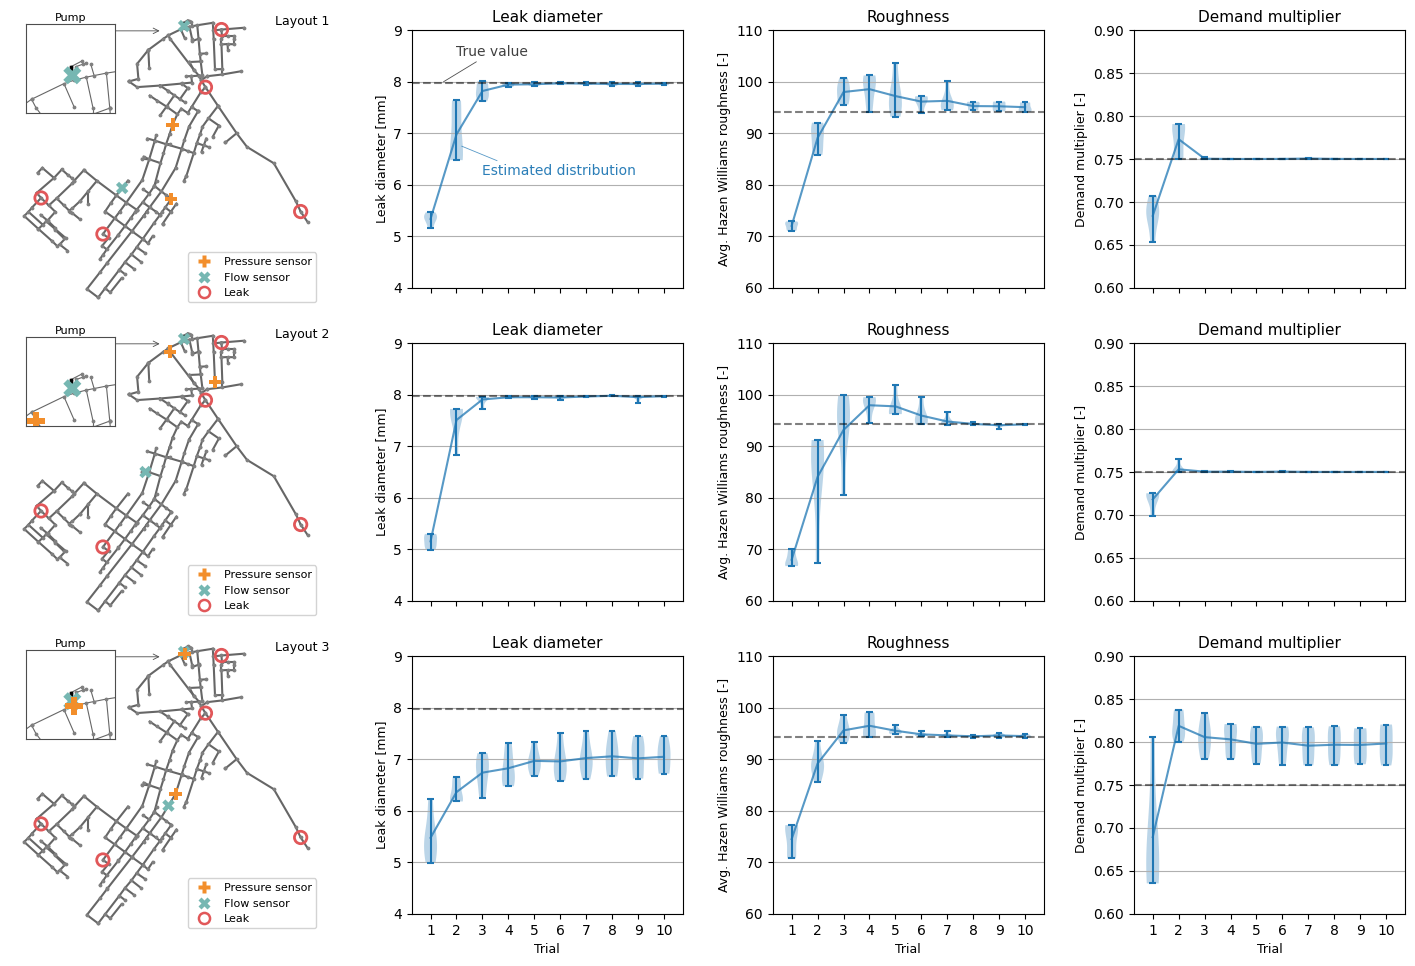

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

# Actual values
actual_values = {
    'leak': 1000 * np.sqrt(4 / np.pi * 5e-5),
    'rough': 1.2 * avg_roughness,
    'demand': 0.75
}

def _rel_errors(df):
    return np.column_stack([
        1000 * np.sqrt(4 / np.pi * df['estimated_leak_area']),
        avg_roughness * df['estimated_roughness'],
        df['estimated_demand']
    ])

# per-layout list of estimate DataFrames (matches the per-layout error cells above)
LAYOUT_ESTIMATES = {
    7: [estimates7_H2Q2_v1, estimates7_H2Q2_v2, estimates7_H2Q2_v3,
        estimates7_H2Q2_v4, estimates7_H2Q2_v5],
    2: [estimates2_H2Q2_v1, estimates2_H2Q2_v2, estimates2_H2Q2_v3,
        estimates2_H2Q2_v4, estimates2_H2Q2_v5],
    4: [estimates4_H2Q2_v1, estimates4_H2Q2_v2, estimates4_H2Q2_v3,
        estimates4_H2Q2_v4, estimates4_H2Q2_v5],
}

LAYOUT_ORDER = [7, 2, 4]
PARAMS = [('Leak diameter', 'o'),
          ('Roughness', 's'),
          ('Demand multiplier', '^')]

fig = plt.figure(figsize=(18, 12))
gs  = fig.add_gridspec(nrows=3, ncols=4,
                       width_ratios=[1.15, 1.0, 1.0, 1.0],
                       hspace=0.05, wspace=0.32)

legend_handles = [
    Line2D([0], [0], marker='P', color='#F28E2B', markersize=8,
           markeredgecolor='none', markeredgewidth=0.5,
           linestyle='None', label='Pressure sensor'),
    Line2D([0], [0], marker='X', color='#76B7B2', markersize=8,
           markeredgecolor='none', markeredgewidth=0.5,
           linestyle='None', label='Flow sensor'),
    Line2D([0], [0], marker='o', color='#E15759', markersize=8, markeredgewidth=1.8,
           linestyle='None', markerfacecolor='None', label='Leak'),
]

for row, lid in enumerate(LAYOUT_ORDER):
    cfg = LAYOUTS[lid]

    # column 0: network with pump inset (no axis ticks, no outer frame)
    ax_net = fig.add_subplot(gs[row, 0])
    plot_pa2_layout(cfg['press'], cfg['flow'], cfg['leak'],
                    ax=ax_net, pump_inset=True)
    ax_net.set_xticks([]); ax_net.set_yticks([])
    for s in ax_net.spines.values():
        s.set_visible(False)
    ax_net.legend(handles=legend_handles, loc='lower right',
                  fontsize=8, framealpha=0.85)

    ax_net.annotate(
        f'Layout {row+1}',
        xy=(0.85, 0.95), xycoords='axes fraction',
        zorder=4, fontsize=9
    )
    # error stack -> mean & std across the replicate runs
    stack = np.stack([_rel_errors(df) for df in LAYOUT_ESTIMATES[lid]])
    mean_err = stack.mean(axis=0)
    std_err  = stack.std(axis=0)
    rounds   = np.arange(1, mean_err.shape[0] + 1)

    # columns 1..3: leak / roughness / demand — nearly square, just a hair wider
    for col, (title, marker) in enumerate(PARAMS, start=1):
        ax = fig.add_subplot(gs[row, col])
        violins = ax.violinplot(stack[:, :, col-1], rounds)
        ax.plot(rounds, mean_err[:, col - 1], c=[0.12156863, 0.46666667, 0.70588235, 0.75       ])
        ax.set_title(title, fontsize=11)
        if row >= 2:
            ax.set_xlabel('Trial', fontsize=9)
        ax.set_ylabel('Relative Error', fontsize=9)
        ax.grid(axis='y')
        #ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.xaxis.set_ticks(rounds)
        ax.set_box_aspect(0.95)   # nearly square, just barely wider than tall
        ax.axhline(list(actual_values.values())[col-1], linestyle='--', c='k', alpha=0.5)
        if col == 1:
            ax.set_ylim(4, 9)
            ax.set_ylabel('Leak diameter [mm]', fontsize=9)
        elif col == 2:
            ax.set_ylim(60, 110)
            ax.set_ylabel('Avg. Hazen Williams roughness [-]', fontsize=9)
        elif col == 3:
            ax.set_ylim(0.6, 0.9)
            ax.set_ylabel('Demand multiplier [-]', fontsize=9)
        if row < 2:
            ax.xaxis.set_ticklabels([])
        if (row == 0) and (col == 1):
            #ax.annotate('True value', (0.75, 8.2), color='0.25')
            ax.annotate(
                'True value',
                xy=(1.5, 8), xycoords='data',
                xytext=(2, 8.5), textcoords='data', color='0.25',
                arrowprops=dict(arrowstyle='-', color='0.3',
                                lw=0.6, mutation_scale=10,
                                shrinkA=0, shrinkB=0),
                zorder=4,
            )

            ax.annotate(
                'Estimated distribution',
                xy=(2.2, 6.75), xycoords='data',
                xytext=(3, 6.2), textcoords='data', color=[0.12156863, 0.46666667, 0.70588235, 0.95       ],
                arrowprops=dict(arrowstyle='-', color=[0.12156863, 0.46666667, 0.70588235, 0.75       ],
                                lw=0.6, mutation_scale=10,
                                shrinkA=0, shrinkB=0, relpos=(0.25, 0.5)),
                zorder=4,
            )

plt.tight_layout()
plt.savefig('../img/fig_8.png', dpi=200, bbox_inches='tight')


In [6]:
for row, lid in enumerate(LAYOUT_ORDER):
    cfg = LAYOUTS[lid]
    print(row)

    error_stack = np.stack([_rel_errors(df) for df in LAYOUT_ESTIMATES[lid]])
    err_leak_diam = np.abs(error_stack[:, 0, 0].mean() - actual_values['leak'])
    pct_err_leak_diam = err_leak_diam / actual_values['leak']
    print('Leak diameter')
    print('\tErr:', err_leak_diam)
    print('\tPct. Err:', 100 * pct_err_leak_diam, '%')

    err_rough = np.abs(error_stack[:, 0, 1].mean() - actual_values['rough'])
    pct_err_rough = err_rough / actual_values['rough']
    print('Roughness')
    print('\tErr:', err_rough)
    print('\tPct. Err:', 100 * pct_err_rough, '%')

    err_demand = np.abs(error_stack[:, 0, 2].mean() - actual_values['demand'])
    pct_err_demand = err_demand / actual_values['demand']
    print('Demand')
    print('\tErr:', err_demand)
    print('\tPct. Err:', 100 * pct_err_demand, '%')

0
Leak diameter
	Err: 2.641439423915176
	Pct. Err: 33.10553372855401 %
Roughness
	Err: 22.198484907977445
	Pct. Err: 23.559018209580735 %
Demand
	Err: 0.06612966099843554
	Pct. Err: 8.81728813312474 %
1
Leak diameter
	Err: 2.8259012755931705
	Pct. Err: 35.41742019358826 %
Roughness
	Err: 26.261884008105298
	Pct. Err: 27.871460873552984 %
Demand
	Err: 0.03197905000340118
	Pct. Err: 4.263873333786824 %
2
Leak diameter
	Err: 2.5047607198321833
	Pct. Err: 31.39252020758224 %
Roughness
	Err: 19.735818786687844
	Pct. Err: 20.945416595052105 %
Demand
	Err: 0.0607374592623775
	Pct. Err: 8.098327901650332 %


In [7]:
for row, lid in enumerate(LAYOUT_ORDER):
    cfg = LAYOUTS[lid]
    print(row)

    error_stack = np.stack([_rel_errors(df) for df in LAYOUT_ESTIMATES[lid]])
    err_leak_diam = np.abs(error_stack[:, -1, 0].mean() - actual_values['leak'])
    pct_err_leak_diam = err_leak_diam / actual_values['leak']
    print('Leak diameter')
    print('\tErr:', err_leak_diam)
    print('\tPct. Err:', 100 * pct_err_leak_diam, '%')

    err_rough = np.abs(error_stack[:, -1, 1].mean() - actual_values['rough'])
    pct_err_rough = err_rough / actual_values['rough']
    print('Roughness')
    print('\tErr:', err_rough)
    print('\tPct. Err:', 100 * pct_err_rough, '%')

    err_demand = np.abs(error_stack[:, -1, 2].mean() - actual_values['demand'])
    pct_err_demand = err_demand / actual_values['demand']
    print('Demand')
    print('\tErr:', err_demand)
    print('\tPct. Err:', 100 * pct_err_demand, '%')

0
Leak diameter
	Err: 0.015996316459165882
	Pct. Err: 0.20048409563245226 %
Roughness
	Err: 0.8368488245883583
	Pct. Err: 0.8881388427576103 %
Demand
	Err: 7.491409058746346e-05
	Pct. Err: 0.009988545411661793 %
1
Leak diameter
	Err: 0.006206820413112268
	Pct. Err: 0.0777909577153204 %
Roughness
	Err: 0.02404321359114192
	Pct. Err: 0.02551680932994632 %
Demand
	Err: 9.071394806259292e-05
	Pct. Err: 0.01209519307501239 %
2
Leak diameter
	Err: 0.9318455594896733
	Pct. Err: 11.678952135030796 %
Roughness
	Err: 0.25230661521416664
	Pct. Err: 0.26777035310604047 %
Demand
	Err: 0.04833529628089184
	Pct. Err: 6.444706170785579 %


In [8]:
err_leak_diam = np.abs(error_stack[:, :, 0].mean() - actual_values['leak'])
pct_err_leak_diam = err_leak_diam / actual_values['leak']
print('Err:', err_leak_diam)
print('Pct. Err:', 100 * pct_err_leak_diam, '%')

Err: 1.2323248951399473
Pct. Err: 15.44490212844737 %


In [9]:
err_rough = np.abs(error_stack[:, :, 1].mean() - actual_values['rough'])
pct_err_rough = err_rough / actual_values['rough']
print('Err:', err_rough)
print('Pct. Err:', 100 * pct_err_rough, '%')

Err: 1.8001369924778174
Pct. Err: 1.9104664287374025 %


In [10]:
err_demand = np.abs(error_stack[:, :, 2].mean() - actual_values['demand'])
pct_err_demand = err_demand / actual_values['demand']
print('Err:', err_demand)
print('Pct. Err:', 100 * pct_err_demand, '%')

Err: 0.04018751556920852
Pct. Err: 5.358335409227802 %
